# Phase space: Wigner and Husimi functions

A classical particle is a point $(x, p)$ in phase space, and an ensemble of particles a density
$\rho(x, p)$ that flows along the trajectories (Liouville's theorem). A quantum state has no such
density, since $x$ and $p$ cannot both be sharp, but the *Wigner function*

$$W(x, p) = \frac{1}{\pi}\int \psi^*(x + y)\,\psi(x - y)\,e^{2ipy}\,\mathrm{d}y$$

comes close: it is real, and its marginals are the position and momentum densities,
$\int W\,\mathrm{d}p = |\psi(x)|^2$ and $\int W\,\mathrm{d}x = |\tilde\psi(p)|^2$. Unlike a probability
density it can be negative, and its negative regions are a signature of interference
(Wigner, Phys. Rev. **40**, 749 (1932)).

The *Husimi function* $Q(x, p) = |\langle x, p|\psi\rangle|^2/2\pi$ is the overlap with a coherent state
centered at $(x, p)$. It is the Wigner function smoothed over a phase space cell of area $\sim\hbar$, which
makes it non-negative but washes out fine structure.

This notebook compares both with classical phase space flow: exactly equal in the harmonic oscillator,
and parting ways in an anharmonic one. `so.wigner()` and `so.husimi()` compute them for a 1d grid;
`so.analyzers.Wigner` and `so.analyzers.Husimi` record them during a propagation.

In [1]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## A gallery of states

A Gaussian has a Gaussian Wigner function, positive everywhere; the only pure states with this property
(Hudson, Rep. Math. Phys. **6**, 249 (1974)). A squeezed state is narrower in $x$ and wider in $p$. The
first excited state of the oscillator reaches the most negative value possible, $W(0, 0) = -1/\pi$. A
*cat state*, two Gaussians at $\pm x_0$, has two positive blobs and between them fringes with spacing
$\pi/x_0$ in $p$, which carry the coherence of the superposition. In the Husimi function (bottom row) the
fringes are gone.

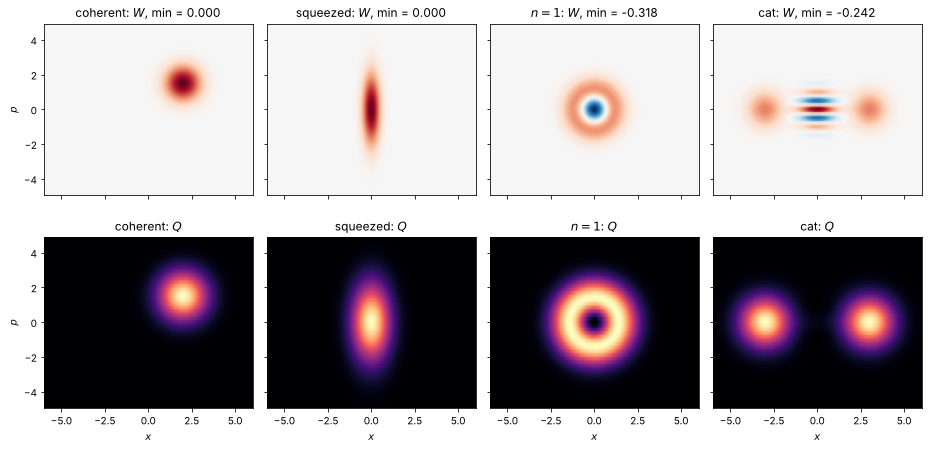

In [3]:
grid = so.Grid1d((-15.0, 15.0), 2**9, so.HarmOscPot(1.0), so.Gaussian1d(0.0, 1.0, 0.0))
_, (ground, first) = so.lowest_eigenstates(grid, 2)
states = {
    "coherent": so.Gaussian1d(2.0, 1.0, 1.5).psi(grid.x_vals),
    "squeezed": so.Gaussian1d(0.0, 0.5, 0.0).psi(grid.x_vals),
    r"$n = 1$": first,
    "cat": (so.Gaussian1d(-3.0, 1.0, 0.0) + so.Gaussian1d(3.0, 1.0, 0.0)).psi(grid.x_vals),
}
lim = dict(x_lim=(-6, 6), p_lim=(-5, 5))

fig, axs = plt.subplots(2, 4, figsize=(13, 6.5), sharex=True, sharey=True)
for (name, psi), ax_w, ax_q in zip(states.items(), *axs, strict=True):
    psi = psi / np.sqrt(np.sum(np.abs(psi) ** 2) * grid.dx)
    x, p, W = so.wigner(grid, psi, **lim)
    so.plotting.plot_phase_space(x, p, W, ax=ax_w, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
    ax_w.set_title(f"{name}: $W$, min = {round(W.min(), 3) + 0.0:.3f}")
    x, p, Q = so.husimi(grid, psi, **lim)
    so.plotting.plot_phase_space(x, p, Q, ax=ax_q)
    ax_q.set_title(f"{name}: $Q$")
for ax in axs.flat:
    ax.set_aspect("equal")
    ax.label_outer()
fig.tight_layout()

## Harmonic oscillator: quantum flow is classical flow

For a Hamiltonian at most quadratic in $x$ and $p$ the Wigner function obeys exactly the classical
Liouville equation (Moyal, Proc. Camb. Phil. Soc. **45**, 99 (1949)). In the oscillator with $\omega = 1$
phase space rotates rigidly with period $2\pi$. We propagate a squeezed state and, next to it, a classical
ensemble sampled from its (positive) initial Wigner function, $x \sim \mathcal{N}(x_0, \sigma^2/2)$,
$p \sim \mathcal{N}(p_0, 1/2\sigma^2)$. Every point of the ensemble moves classically, so the dots trace the
quantum $W$ at all times.

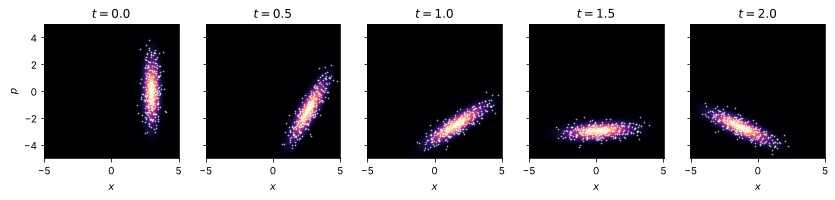

In [4]:
def classical_ensemble(x0, sigma, p0, n=2000, rng=0):
    # samples of the Wigner function of so.Gaussian1d(x0, sigma, p0)
    rng = np.random.default_rng(rng)
    return rng.normal(x0, sigma / np.sqrt(2), n), rng.normal(p0, 1 / (np.sqrt(2) * sigma), n)


def verlet(x, p, force, dt, n_steps):
    # velocity Verlet, the classical analogue of the split operator step
    for _ in range(n_steps):
        p = p + 0.5 * dt * force(x)
        x = x + dt * p
        p = p + 0.5 * dt * force(x)
    return x, p


x0, sigma, p0 = 3.0, 0.5, 0.0
grid = so.Grid1d((-15.0, 15.0), 2**9, so.HarmOscPot(1.0), so.Gaussian1d(x0, sigma, p0))
wig = so.analyzers.Wigner(x_lim=(-5, 5), p_lim=(-5, 5))
wig(grid)
dt, every = 0.01, 50  # a snapshot every 0.5
so.SplitOperator().propagate(grid, dt, 4 * every, callback=wig, every=every)

xc, pc = classical_ensemble(x0, sigma, p0)
fig, axs = plt.subplots(1, 5, figsize=(14, 3.2), sharey=True)
for n, ax in enumerate(axs):
    so.plotting.plot_phase_space(wig.x, wig.p, wig.W[n], ax=ax)
    ax.plot(xc[:300], pc[:300], ".", color="w", ms=1.5, alpha=0.6)
    ax.set(title=f"$t = {wig.t[n]:.1f}$", aspect="equal")
    ax.label_outer()
    xc, pc = verlet(xc, pc, lambda x: -x, dt, every)

## Anharmonic oscillator: where quantum and classical part

In the quartic oscillator $V = \lambda x^4$ the period depends on the energy, so a classical ensemble
shears into a spiral that winds up ever more tightly: it *filaments*, but stays positive. The quantum
$W$ follows the classical flow at first, up to corrections of order $\hbar^2 V'''$. Once the spiral arms
come closer than $\sim\hbar$, they interfere: $W$ develops negative fringes between the arms and the
spiral dissolves into an interference pattern. The Husimi function cannot resolve the arms, so it looks
like a smoothed classical density.

Below, $W$ (top) and the classical ensemble as a histogram (bottom) at a few times.

In [5]:
lam = 0.05


class Quartic(so.Potential1d):
    is_time_dependent = False

    def V(self, x, t):
        return lam * x**4


def force(x):
    return -4 * lam * x**3


x0, sigma, p0 = 4.0, 0.7, 0.0
grid = so.Grid1d((-10.0, 10.0), 2**9, Quartic(), so.Gaussian1d(x0, sigma, p0))
print(f"E = {grid.energy():.2f}")
dt, every = 0.005, 100  # a snapshot every 0.5
lim = dict(x_lim=(-6, 6), p_lim=(-9, 9))
wig = so.analyzers.Wigner(**lim)
hus = so.analyzers.Husimi(sigma=sigma, **lim)
obs = so.analyzers.Observables()
callbacks = [wig, hus, obs]
for c in callbacks:
    c(grid)
so.SplitOperator().propagate(grid, dt, 40 * every, callback=callbacks, every=every)

shown = [0, 2, 4, 8, 16, 40]  # snapshot numbers
bins = [np.linspace(-6, 6, 97), np.linspace(-9, 9, 97)]
xc, pc = classical_ensemble(x0, sigma, p0, n=30_000)
hist = [np.histogram2d(xc, pc, bins=bins, density=True)[0]]
for n in range(1, shown[-1] + 1):
    xc, pc = verlet(xc, pc, force, dt, every)
    if n in shown:
        hist.append(np.histogram2d(xc, pc, bins=bins, density=True)[0])

E = 14.50


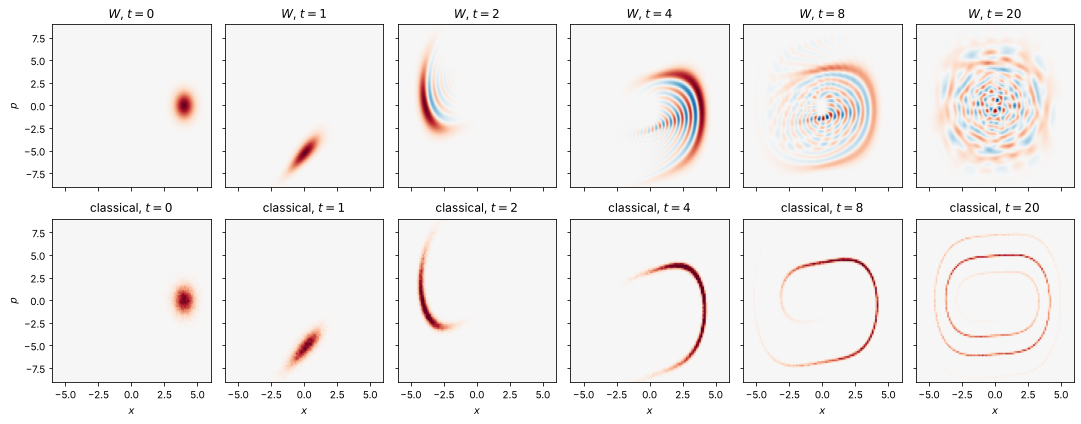

In [6]:
fig, axs = plt.subplots(2, len(shown), figsize=(15, 6), sharex=True, sharey=True)
centers = [(b[1:] + b[:-1]) / 2 for b in bins]
for ax_q, ax_c, n, h in zip(*axs, shown, hist, strict=True):
    vmax = np.abs(wig.W[n]).max()
    so.plotting.plot_phase_space(wig.x, wig.p, wig.W[n], ax=ax_q, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax_q.set_title(f"$W$, $t = {wig.t[n]:.0f}$")
    so.plotting.plot_phase_space(*centers, h, ax=ax_c, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax_c.set_title(f"classical, $t = {wig.t[n]:.0f}$")
for ax in axs.flat:
    ax.label_outer()
fig.tight_layout()

A measure of how non-classical the state is: the *negative volume*
$\delta = \int\!\!\int |W|\,\mathrm{d}x\,\mathrm{d}p - 1$, which is zero for a positive $W$
(Kenfack and Życzkowski, J. Opt. B **6**, 396 (2004)). It stays near zero up to $t \approx 1.5$, a bit less than half a period,
while the quantum state follows the classical flow, and grows once the arms interfere.

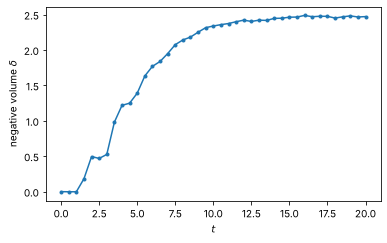

In [7]:
dA = (wig.x[1] - wig.x[0]) * (wig.p[1] - wig.p[0])
negative_volume = np.sum(np.abs(wig.W), axis=(1, 2)) * dA - 1
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(wig.t, negative_volume, "o-", ms=3)
ax.set(xlabel="$t$", ylabel=r"negative volume $\delta$");

Interference changes $W$ completely, but averages such as $\langle x\rangle$ hardly notice: quantum and
classical $\langle x\rangle$ damp out in the same way, since the packet spreads around the orbit in both.
The difference shows up later. The quantum spectrum is discrete, so the phases $e^{-iE_nt}$ of the
eigenstates in the packet come back into step after a while and the oscillation *revives* in part, here
around $t \approx 150$. The classical ensemble keeps filamenting and never revives.

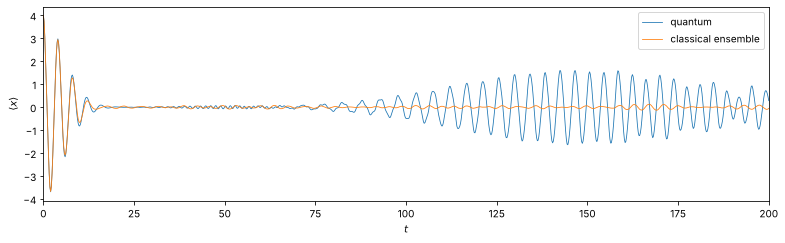

In [8]:
t_long, dt_long, every_long = 200.0, 0.01, 20
grid = so.Grid1d((-10.0, 10.0), 2**9, Quartic(), so.Gaussian1d(x0, sigma, p0))
obs = so.analyzers.Observables()
obs(grid)
so.SplitOperator().propagate(grid, dt_long, int(t_long / dt_long), callback=obs, every=every_long)

xc, pc = classical_ensemble(x0, sigma, p0, n=5000)
x_classical = [xc.mean()]
for _ in range(len(obs) - 1):
    xc, pc = verlet(xc, pc, force, dt_long, every_long)
    x_classical.append(xc.mean())

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(obs.t, obs.position, lw=0.8, label="quantum")
ax.plot(obs.t, x_classical, lw=0.8, label="classical ensemble")
ax.set(xlabel="$t$", ylabel=r"$\langle x\rangle$", xlim=(0, t_long))
ax.legend();

At the largest $\langle x\rangle$ of the revival, part of the Wigner function has gathered again near
the starting point $(x_0, 0)$, as a crescent on top of a sea of fringes:

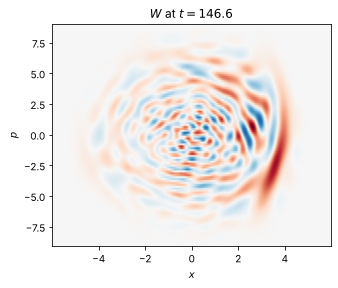

In [9]:
late = obs.t > 100
t_rev = obs.t[late][np.argmax(obs.position[late])]
grid = so.Grid1d((-10.0, 10.0), 2**9, Quartic(), so.Gaussian1d(x0, sigma, p0))
so.SplitOperator().propagate(grid, dt_long, int(round(t_rev / dt_long)))
fig, ax = plt.subplots(figsize=(5, 4))
so.plotting.plot_phase_space(*so.wigner(grid, **lim), ax=ax)
ax.set_title(f"$W$ at $t = {grid.t:.1f}$");

The Husimi function at the same times. It never goes negative; at late times it is a smeared ring
around the energy shell, close to the classical density smoothed over a cell of size $\sigma \times 1/\sigma$.

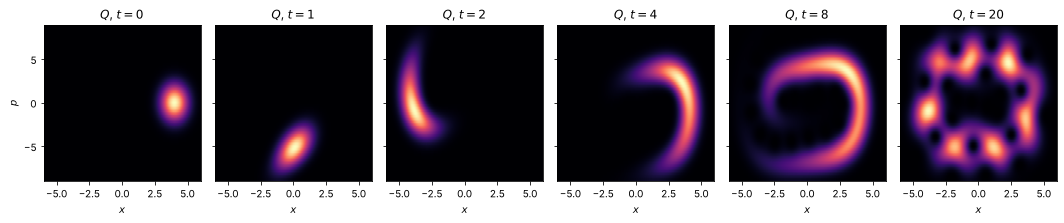

In [10]:
fig, axs = plt.subplots(1, len(shown), figsize=(15, 3.2), sharey=True)
for ax, n in zip(axs, shown, strict=True):
    so.plotting.plot_phase_space(hus.x, hus.p, hus.W[n], ax=ax)
    ax.set_title(f"$Q$, $t = {hus.t[n]:.0f}$")
    ax.label_outer()
fig.tight_layout()

## A cat state: fringes in phase space become fringes in space

The two blobs of a cat state rotate around the origin in the oscillator. At $t = \pi/2$ they sit at
$p = \pm x_0$ on top of each other in $x$, and the fringes between them now run along $x$. Since the
position density is the $p$-marginal of $W$, the fringes show up as an interference pattern in
$|\psi(x)|^2$ with spacing $\pi/x_0$, just like two plane waves $e^{\pm ix_0x}$.

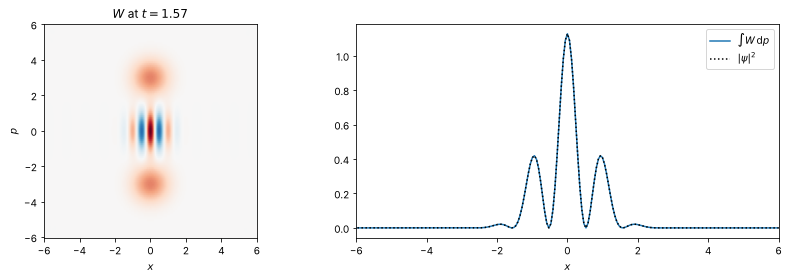

In [11]:
x0 = 3.0
psi0 = so.Gaussian1d(-x0, 1.0, 0.0) + so.Gaussian1d(x0, 1.0, 0.0)
grid = so.Grid1d((-15.0, 15.0), 2**9, so.HarmOscPot(1.0), psi0)
grid.renormalize_psi()
so.SplitOperator().propagate(grid, 0.01, int(round(np.pi / 2 / 0.01)))

x, p, W = so.wigner(grid, x_lim=(-6, 6), p_lim=(-6, 6))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
so.plotting.plot_phase_space(x, p, W, ax=ax1)
ax1.set(title=rf"$W$ at $t = {grid.t:.2f}$", aspect="equal")
ax2.plot(x, np.sum(W, axis=1) * (p[1] - p[0]), label=r"$\int W\,\mathrm{d}p$")
ax2.plot(grid.x_vals, grid.density, "k:", label=r"$|\psi|^2$")
ax2.set(xlim=(-6, 6), xlabel="$x$")
ax2.legend()
fig.tight_layout()

Things to try:

* Make the quartic oscillator less anharmonic (smaller $\lambda$, or $V = x^2/2 + \lambda x^4$): the quantum and
  classical pictures then agree for longer.
* Wait longer in the quartic oscillator: at multiples of $T_\mathrm{rev} \approx 2\pi/|E''(n)|$ the state
  partly revives, which no classical ensemble does.
* Use `so.husimi(grid, sigma=...)` with different widths: a narrow $\sigma$ resolves $x$ and blurs $p$, and
  the other way round.
* Look at the eigenstates from `so.lowest_eigenstates()`: their Wigner functions are rings with
  alternating signs, concentrated on the classical orbit of the same energy.